In [1]:
from gauche.dataloader import MolPropLoader

loader = MolPropLoader()
loader.load_benchmark("Photoswitch")

# We use the fragprints representations
loader.featurize('ecfp_fragprints')
X = loader.features
y = loader.labels

Found 13 invalid labels [nan nan nan nan nan nan nan nan nan nan nan nan nan] at indices [41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 158]
To turn validation off, use dataloader.read_csv(..., validate=False).


In [2]:
import numpy as np
import time
import torch
import warnings

from botorch.acquisition import LogExpectedImprovement
from botorch.exceptions import BadInitialCandidatesWarning
from botorch.exceptions import InputDataWarning
from botorch.fit import fit_gpytorch_mll
from crda_gp.bo import initialize_model
from crda_gp.bo import optimize_acqf_and_get_observation
from sklearn.model_selection import train_test_split

N_TRIALS = 20 
holdout_set_size = 0.95
N_ITERS = 20
verbose = False

warnings.filterwarnings('ignore', category=BadInitialCandidatesWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings("ignore", category=InputDataWarning)
# warnings.filterswarnings

best_observed_all_ei = []

for trial in range(1, N_TRIALS + 1):

    print(f"\nTrial {trial:>2} of {N_TRIALS}", end="")
    best_observed_ei = []

    # Generate initial training data and initialize model
    train_x_ei, heldout_x_ei, train_y_ei, heldout_y_ei = train_test_split(X, y, test_size=holdout_set_size, random_state=trial)
    best_observed_value_ei = torch.tensor(np.max(train_y_ei))

    # Convert numpy arrays to PyTorch tensors and flatten the label vectors
    train_x_ei = torch.tensor(train_x_ei.astype(np.float64))
    heldout_x_ei = torch.tensor(heldout_x_ei.astype(np.float64))
    train_y_ei = torch.tensor(train_y_ei.astype(np.float64))
    heldout_y_ei = torch.tensor(heldout_y_ei.astype(np.float64))

    model_ei, mll_ei = initialize_model(train_x_ei, train_y_ei)
    # print(type(model_ei))
    # print(type(mll_ei))
    best_observed_ei.append(best_observed_value_ei)

    for iteration in range(1, N_ITERS + 1):

        t0 = time.time()

        # fit the model

        fit_gpytorch_mll(mll=mll_ei)

        # Use analytic acquisition function for batch size of 1.
        LogEI = LogExpectedImprovement(model=model_ei, best_f=(train_y_ei.to(train_y_ei)).max())

        new_x_ei, new_obj_ei, heldout_x_ei, heldout_y_ei = optimize_acqf_and_get_observation(LogEI, heldout_inputs=heldout_x_ei, heldout_outputs=heldout_y_ei)

        # update the training points 
        train_x_ei = torch.cat([train_x_ei, new_x_ei])
        train_y_ei = torch.cat([train_y_ei, new_obj_ei])

        best_value_ei = torch.max(new_obj_ei, best_observed_ei[-1])
        best_observed_ei.append(best_value_ei.squeeze())

        # Reinitialize the model
        model_ei, mll_ei = initialize_model(train_x_ei, train_y_ei, model_ei.state_dict())

        t1 = time.time()

        if verbose:
            print(f"\nBatch {iteration:>2} | best_value (EI): {best_value_ei} | time: {t1 - t0:4.2f}.", end="")
        else:
            print(".", end="")
    
    best_observed_all_ei.append(torch.hstack(best_observed_ei))


Trial  1 of 20....................
Trial  2 of 20....................
Trial  3 of 20....................
Trial  4 of 20....................
Trial  5 of 20....................
Trial  6 of 20....................
Trial  7 of 20....................
Trial  8 of 20....................
Trial  9 of 20....................
Trial 10 of 20....................
Trial 11 of 20....................
Trial 12 of 20....................
Trial 13 of 20....................
Trial 14 of 20....................
Trial 15 of 20....................
Trial 16 of 20....................
Trial 17 of 20....................
Trial 18 of 20....................
Trial 19 of 20....................
Trial 20 of 20....................

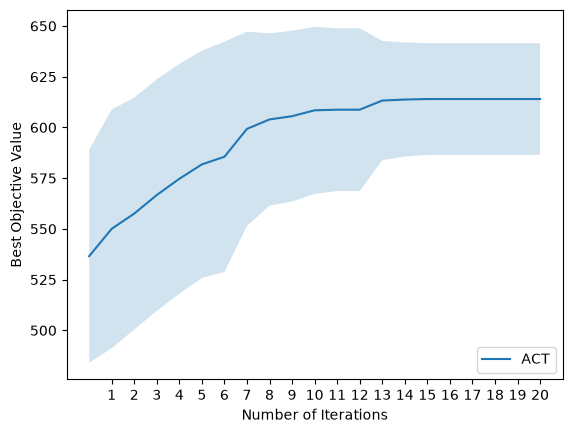

In [3]:
from crda_gp.bo import plot_confidence
plot_confidence(best_observed=best_observed_all_ei)

In [4]:
import gpytorch
from crda_gp.models import ARDExactGPModel_Sparse
from crda_gp.utils import set_seed

set_seed()

X_tensor, y_tensor = torch.tensor(X, dtype=torch.double), torch.tensor(y).squeeze()
likelihood_aug = gpytorch.likelihoods.GaussianLikelihood()
model_aug = ARDExactGPModel_Sparse(X_tensor, y_tensor, likelihood_aug)

In [5]:
from crda_gp.utils import train_step
train_step(X_train=X_tensor,
           y_train=y_tensor,
           model=model_aug,
           likelihood=likelihood_aug)

Iter: 10/100 | Loss: 1137.993 | Noise: 1.284
Iter: 20/100 | Loss: 738.932 | Noise: 1.910
Iter: 30/100 | Loss: 529.429 | Noise: 2.439
Iter: 40/100 | Loss: 376.948 | Noise: 2.865
Iter: 50/100 | Loss: 284.181 | Noise: 3.217
Iter: 60/100 | Loss: 235.475 | Noise: 3.521
Iter: 70/100 | Loss: 208.175 | Noise: 3.795
Iter: 80/100 | Loss: 190.756 | Noise: 4.050
Iter: 90/100 | Loss: 178.281 | Noise: 4.293
Iter: 100/100 | Loss: 168.572 | Noise: 4.527


In [6]:
import pandas as pd
import gpytorch

set_seed()

with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_dist = likelihood_aug(model_aug(X_tensor))
    y_new_aug = pred_dist.mean

residual = y_tensor - y_new_aug
corr = abs(pd.DataFrame(X).corrwith(pd.Series(residual.detach().numpy())))

preturb_idx= corr[abs(corr) < corr.mean().item()].sort_values(ascending=False).index.values
preturb_idx

array([1057,  849, 1816,  245, 2017, 1758,  956, 1355, 1516, 1345,  156,
       1452, 1712,  556,  514, 1788,  574, 1145, 1637, 1209,  374,  349,
        237,  759, 1152,  952, 1146,  845,  150,  761,  172,  766,  501,
        662,   62,  235, 1247, 1176,  701, 1487, 1504, 1736,  731, 1036,
       1475, 2125, 1567,  609,  409, 1602,  218,  415,   50, 1227, 1300,
        195,  926,   58,  969, 1616, 1521,  939, 1111,  754, 2046, 1977,
       1386,  971, 1950,  474,  664,   56,  155,  914,  906,  484,  893,
        866, 1754, 1060,   48,  505,  637, 1391, 1671,  238,  405,  733,
       1538,  630, 1515, 1157, 1191, 2121, 2114, 1013,  325, 2064, 1417,
       1260, 1400, 1316, 1664,   65, 2113, 2055, 1999,  530,    3, 2009,
       1645, 1666, 1767, 1535,  675,  471,  252,   27, 1299, 1479,  184,
       1974, 1807, 1185,  163,  462,  351, 1992,  625, 1414,  383,  935,
        542, 1346,  537, 1648, 1233, 1985,  928, 1424,  281, 1253, 1811,
       1701, 1799,  314, 1509, 1962,  196,  190, 15

In [7]:
from crda_gp.crda import CRDA_function
set_seed(42)
X_CRDA_tensor, y_CRDA_tensor, _, _ = CRDA_function(X_tensor, y_tensor, model=model_aug, likelihood=likelihood_aug, perturb_idx=preturb_idx, p=0.1)


c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [8]:
# Running the BO on the data
# Bayesian Optimization stuff

N_TRIALS = 20 
holdout_set_size = 0.95
N_ITERS = 20
verbose = False

warnings.filterwarnings('ignore', category=BadInitialCandidatesWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

best_observed_all_ei, best_random_all = [], []

for trial in range(1, N_TRIALS + 1):

    print(f"\nTrial {trial:>2} of {N_TRIALS}", end="")
    best_observed_ei = []

    # Generate initial training data and initialize model
    train_x_ei, heldout_x_ei, train_y_ei, heldout_y_ei = train_test_split(X_CRDA_tensor, y_CRDA_tensor, test_size=holdout_set_size, random_state=trial)
    best_observed_value_ei = torch.max(train_y_ei)

    # Convert numpy arrays to PyTorch tensors and flatten the label vectors
    train_x_ei = train_x_ei.double()
    heldout_x_ei = heldout_x_ei.double()
    train_y_ei = train_y_ei.double()
    heldout_y_ei = heldout_y_ei.double()

    model_ei, mll_ei = initialize_model(train_x_ei, train_y_ei.unsqueeze(-1))
    # print(type(model_ei))
    # print(type(mll_ei))
    best_observed_ei.append(best_observed_value_ei)

    for iteration in range(1, N_ITERS + 1):

        t0 = time.time()

        # fit the model

        fit_gpytorch_mll(mll=mll_ei)

        # Use analytic acquisition function for batch size of 1.
        LogEI = LogExpectedImprovement(model=model_ei, best_f=(train_y_ei.to(train_y_ei)).max())

        new_x_ei, new_obj_ei, heldout_x_ei, heldout_y_ei = optimize_acqf_and_get_observation(LogEI, heldout_inputs=heldout_x_ei, heldout_outputs=heldout_y_ei)

        # update the training points 
        train_x_ei = torch.cat([train_x_ei, new_x_ei])
        train_y_ei = torch.cat([train_y_ei, new_obj_ei])

        best_value_ei = torch.max(new_obj_ei, best_observed_ei[-1])
        best_observed_ei.append(best_value_ei.squeeze())

        # Reinitialize the model
        model_ei, mll_ei = initialize_model(train_x_ei, train_y_ei.unsqueeze(-1),model_ei.state_dict())

        t1 = time.time()

        if verbose:
            print(f"\nBatch {iteration:>2} | best_value (EI): {best_value_ei} | time: {t1 - t0:4.2f}.", end="")
        else:
            print(".", end="")
    
    best_observed_all_ei.append(torch.hstack(best_observed_ei))


Trial  1 of 20....................
Trial  2 of 20....................
Trial  3 of 20....................
Trial  4 of 20....................
Trial  5 of 20....................
Trial  6 of 20....................
Trial  7 of 20....................
Trial  8 of 20....................
Trial  9 of 20....................
Trial 10 of 20....................
Trial 11 of 20....................
Trial 12 of 20....................
Trial 13 of 20....................
Trial 14 of 20....................
Trial 15 of 20....................
Trial 16 of 20....................
Trial 17 of 20....................
Trial 18 of 20....................
Trial 19 of 20....................
Trial 20 of 20....................

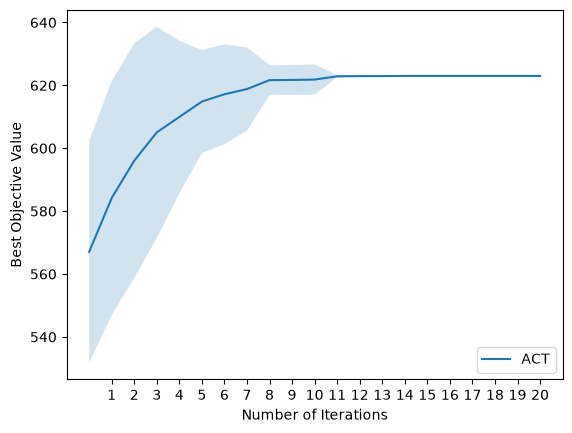

In [9]:
plot_confidence(best_observed=best_observed_all_ei)